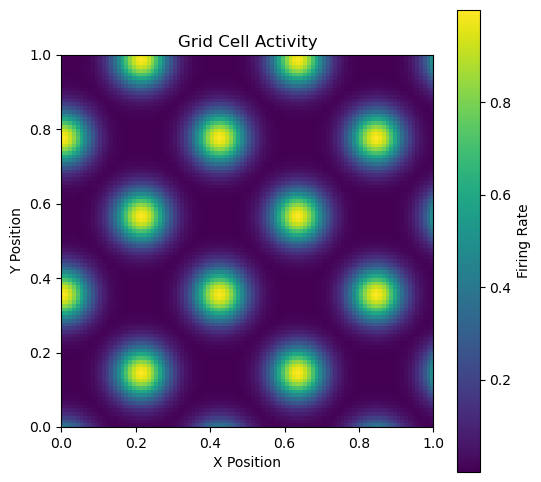

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def generate_grid_cell_response(position, grid_spacing, orientation, phase_offset, sigma, max_firing_rate):
    """
    Generates the response of a grid cell based on the animal's position.

    Parameters:
    - position: A 2D numpy array representing the animal's current position [x, y].
    - grid_spacing: The distance between grid peaks (lambda).
    - orientation: The orientation of the grid axes (in radians).
    - phase_offset: A 2D numpy array representing the phase offset of the grid cell [phi_x, phi_y].
    - sigma: The width of the Gaussian tuning curve.
    - max_firing_rate: The maximum firing rate at the grid peaks.

    Returns:
    - response: The firing rate of the grid cell at the given position.
    """
    # Rotate the position by the grid orientation
    rotation_matrix = np.array([[np.cos(orientation), -np.sin(orientation)],
                                [np.sin(orientation),  np.cos(orientation)]])
    rotated_position = np.dot(rotation_matrix, position)

    # Compute the phase of the grid cell at the current position
    phase_x = (rotated_position[0] + phase_offset[0]) % grid_spacing
    phase_y = (rotated_position[1] + phase_offset[1]) % grid_spacing

    # Compute the grid cell response using a Gaussian function centered at each grid peak
    response_x = np.exp(-0.5 * ((phase_x - grid_spacing / 2) ** 2) / sigma ** 2)
    response_y = np.exp(-0.5 * ((phase_y - grid_spacing / 2) ** 2) / sigma ** 2)

    # Combine responses from both axes to get the final response and scale by max_firing_rate
    response = max_firing_rate * response_x * response_y

    return response

def plot_grid_cell_activity(grid_size, grid_spacing, orientation, phase_offset, sigma, max_firing_rate, resolution=100):
    """
    Plots the grid cell activity over a 2D environment.

    Parameters:
    - grid_size: The size of the environment (width, height).
    - grid_spacing: The distance between grid peaks (lambda).
    - orientation: The orientation of the grid axes (in radians).
    - phase_offset: A 2D numpy array representing the phase offset of the grid cell [phi_x, phi_y].
    - sigma: The width of the Gaussian tuning curve.
    - max_firing_rate: The maximum firing rate at the grid peaks.
    - resolution: The number of points to sample along each axis.
    """
    x_values = np.linspace(0, grid_size[0], resolution)
    y_values = np.linspace(0, grid_size[1], resolution)
    grid_activity = np.zeros((resolution, resolution))

    for i, x in enumerate(x_values):
        for j, y in enumerate(y_values):
            position = np.array([x, y])
            grid_activity[j, i] = generate_grid_cell_response(position, grid_spacing, orientation, phase_offset, sigma, max_firing_rate)

    plt.figure(figsize=(6, 6))
    plt.imshow(grid_activity, extent=(0, grid_size[0], 0, grid_size[1]), origin='lower', cmap='viridis')
    plt.colorbar(label='Firing Rate')
    plt.title('Grid Cell Activity')
    plt.xlabel('X Position')
    plt.ylabel('Y Position')
    plt.show()

# Example parameters
grid_size = [1.0, 1.0]  # 1x1 meter environment
grid_spacing = 0.3      # Grid spacing (lambda) of 0.3 meters
orientation = np.pi / 4  # 45 degree orientation
phase_offset = np.array([0.1, 0.2])  # Phase offset in meters
sigma = 0.05  # Width of the Gaussian tuning curve (sigma)
max_firing_rate = 1.0  # Maximum firing rate at the grid peaks

# Plot grid cell activity
plot_grid_cell_activity(grid_size, grid_spacing, orientation, phase_offset, sigma, max_firing_rate)

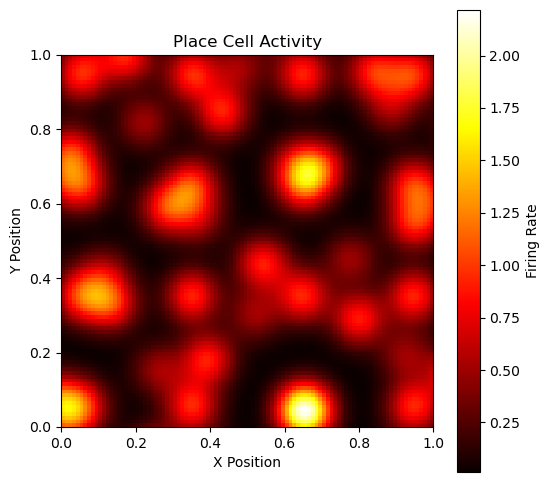

In [2]:
# import numpy as np
# import matplotlib.pyplot as plt

# def generate_grid_cell_response(position, grid_spacing, orientation, phase_offset, sigma, max_firing_rate):
#     rotation_matrix = np.array([[np.cos(orientation), -np.sin(orientation)],
#                                 [np.sin(orientation),  np.cos(orientation)]])
#     rotated_position = np.dot(rotation_matrix, position)
#     phase_x = (rotated_position[0] + phase_offset[0]) % grid_spacing
#     phase_y = (rotated_position[1] + phase_offset[1]) % grid_spacing
#     response_x = np.exp(-0.5 * ((phase_x - grid_spacing / 2) ** 2) / sigma ** 2)
#     response_y = np.exp(-0.5 * ((phase_y - grid_spacing / 2) ** 2) / sigma ** 2)
#     response = max_firing_rate * response_x * response_y
#     return response

def generate_place_cell_activity(grid_cell_responses, weights):
    # Weighted sum of grid cell responses
    place_cell_response = np.dot(weights, grid_cell_responses)
    # Apply a nonlinearity, e.g., ReLU
    place_cell_response = np.maximum(0, place_cell_response)
    return place_cell_response

def plot_place_cell_activity(grid_size, grid_cell_params, place_cell_weights, resolution=100):
    x_values = np.linspace(0, grid_size[0], resolution)
    y_values = np.linspace(0, grid_size[1], resolution)
    place_cell_activity = np.zeros((resolution, resolution))

    for i, x in enumerate(x_values):
        for j, y in enumerate(y_values):
            position = np.array([x, y])
            grid_cell_responses = np.array([
                generate_grid_cell_response(position, *params) for params in grid_cell_params
            ])
            place_cell_activity[j, i] = generate_place_cell_activity(grid_cell_responses, place_cell_weights)

    plt.figure(figsize=(6, 6))
    plt.imshow(place_cell_activity, extent=(0, grid_size[0], 0, grid_size[1]), origin='lower', cmap='hot')
    plt.colorbar(label='Firing Rate')
    plt.title('Place Cell Activity')
    plt.xlabel('X Position')
    plt.ylabel('Y Position')
    plt.show()

# Example parameters
grid_size = [1.0, 1.0]  # 1x1 meter environment
grid_cell_params = [
    (0.3, 0, np.array([0.1, 0.1]), 0.05, 1.0),  # Grid cell 1
    (0.3, np.pi / 3, np.array([0.15, 0.15]), 0.05, 1.0),  # Grid cell 2
    (0.3, 2 * np.pi / 3, np.array([0.2, 0.2]), 0.05, 1.0)  # Grid cell 3
]

# Random weights for place cell
place_cell_weights = np.random.rand(len(grid_cell_params))

# Plot place cell activity
plot_place_cell_activity(grid_size, grid_cell_params, place_cell_weights)

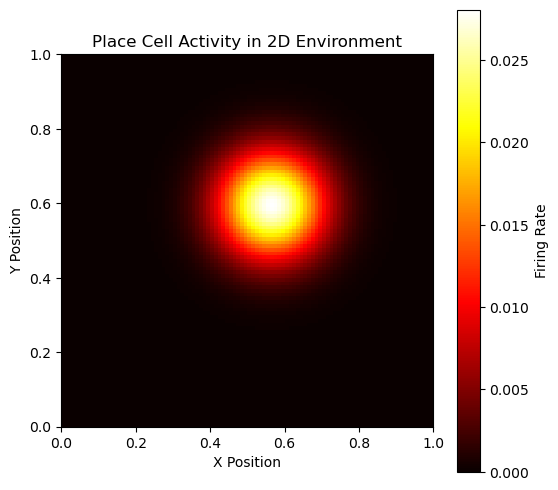

In [59]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

def generate_grid_cell_response_2d(position, grid_spacing, orientation, phase_offset, sigma, max_firing_rate):
    """
    Generates the response of a grid cell in 2D space based on the animal's position.

    Parameters:
    - position: A 2D numpy array representing the animal's current position [x, y].
    - grid_spacing: The distance between grid peaks (lambda).
    - orientation: The orientation of the grid axes (in radians).
    - phase_offset: A 2D numpy array representing the phase offset of the grid cell [phi_x, phi_y].
    - sigma: The width of the Gaussian tuning curve.
    - max_firing_rate: The maximum firing rate at the grid peaks.

    Returns:
    - response: The firing rate of the grid cell at the given position.
    """
    rotation_matrix = np.array([[np.cos(orientation), -np.sin(orientation)],
                                [np.sin(orientation),  np.cos(orientation)]])
    rotated_position = np.dot(rotation_matrix, position)

    phase_x = (rotated_position[0] + phase_offset[0]) % grid_spacing
    phase_y = (rotated_position[1] + phase_offset[1]) % grid_spacing

    response_x = np.exp(-0.5 * ((phase_x - grid_spacing / 2) ** 2) / sigma ** 2)
    response_y = np.exp(-0.5 * ((phase_y - grid_spacing / 2) ** 2) / sigma ** 2)

    response = max_firing_rate * response_x * response_y
    return response

def generate_place_cell_activity_2d(grid_cell_responses, weights):
    """
    Combines grid cell responses to generate the activity of a place cell in 2D.

    Parameters:
    - grid_cell_responses: A numpy array of responses from multiple grid cells.
    - weights: A numpy array of weights corresponding to each grid cell.

    Returns:
    - place_cell_response: The combined firing rate of the place cell.
    """
    place_cell_response = np.dot(weights, grid_cell_responses)
    place_cell_response = np.maximum(0, place_cell_response)  # ReLU nonlinearity
    return place_cell_response

def plot_place_cell_activity_2d(grid_size, grid_cell_params, place_cell_weights, resolution=100):
    """
    Plots the place cell activity over a 2D environment.

    Parameters:
    - grid_size: The size of the environment (width, height).
    - grid_cell_params: A list of tuples, each containing parameters for a grid cell.
    - place_cell_weights: The weights used to combine grid cell responses into place cell activity.
    - resolution: The number of points to sample along each axis.
    """
    x_values = np.linspace(0, grid_size[0], resolution)
    y_values = np.linspace(0, grid_size[1], resolution)
    place_cell_activity = np.zeros((resolution, resolution))

    for i, x in enumerate(x_values):
        for j, y in enumerate(y_values):
            position = np.array([x, y])
            grid_cell_responses = np.array([
                generate_grid_cell_response_2d(position, *params) for params in grid_cell_params
            ])
            place_cell_activity[j, i] = generate_place_cell_activity_2d(grid_cell_responses, place_cell_weights)

    
    place_cell_activity[place_cell_activity < np.max(place_cell_activity)*0.85] = 0
    place_cell_activity_smoothed = gaussian_filter(place_cell_activity, sigma=10.0)

    plt.figure(figsize=(6, 6))
    plt.imshow(place_cell_activity_smoothed, extent=(0, grid_size[0], 0, grid_size[1]), origin='lower', cmap='hot')
    plt.colorbar(label='Firing Rate')
    plt.title('Place Cell Activity in 2D Environment')
    plt.xlabel('X Position')
    plt.ylabel('Y Position')
    plt.show()

# Define a systematic way to generate N grid cells in 2D
N = 100  # Number of grid cells
grid_size = [1.0, 1.0]  # Size of the 2D environment (width, height)
max_firing_rate = 100.0  # Maximum firing rate of each grid cell

grid_cell_params = []
for i in range(N):
    grid_spacing = grid_size[0] / (i + 1)
    orientation = np.random.uniform(0, np.pi)  # Random orientation between 0 and pi
    phase_offset = np.random.uniform(0, grid_spacing, size=2)  # Random phase offset in 2D
    sigma = grid_spacing / 10  # Tuning width relative to grid spacing
    grid_cell_params.append((grid_spacing, orientation, phase_offset, sigma, max_firing_rate))

# Define random weights for place cell (adjusted to ensure a single peak)
place_cell_weights = np.random.rand(N)
place_cell_weights /= np.sum(place_cell_weights)  # Normalize weights


# Plot place cell activity in 2D
plot_place_cell_activity_2d(grid_size, grid_cell_params, place_cell_weights)

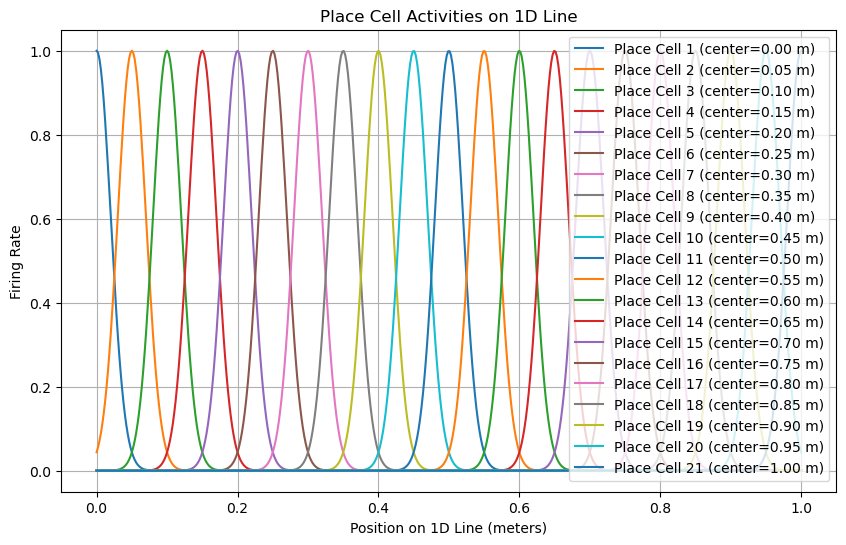

In [7]:
import numpy as np
import matplotlib.pyplot as plt

def generate_place_cell_response_1d(position, center, sigma, max_firing_rate):
    """
    Generates the response of a place cell in 1D space based on the animal's position.

    Parameters:
    - position: A scalar representing the animal's current position on a 1D line.
    - center: The center position of the place cell's activity.
    - sigma: The width of the Gaussian tuning curve.
    - max_firing_rate: The maximum firing rate at the center of the place field.

    Returns:
    - response: The firing rate of the place cell at the given position.
    """
    response = max_firing_rate * np.exp(-0.5 * ((position - center) ** 2) / sigma ** 2)
    return response

def plot_place_cells_1d(line_length, place_cell_centers, sigma, max_firing_rate, resolution=500):
    """
    Plots the activity of multiple place cells along a 1D line.

    Parameters:
    - line_length: The length of the 1D environment.
    - place_cell_centers: A list of centers where each place cell is centered.
    - sigma: The width of the Gaussian tuning curve for each place cell.
    - max_firing_rate: The maximum firing rate at the center of each place field.
    - resolution: The number of points to sample along the 1D line.
    """
    positions = np.linspace(0, line_length, resolution)
    place_cell_activities = np.zeros((len(place_cell_centers), resolution))

    for i, center in enumerate(place_cell_centers):
        for j, pos in enumerate(positions):
            place_cell_activities[i, j] = generate_place_cell_response_1d(pos, center, sigma, max_firing_rate)

    plt.figure(figsize=(10, 6))
    for i, center in enumerate(place_cell_centers):
        plt.plot(positions, place_cell_activities[i], label=f'Place Cell {i+1} (center={center:.2f} m)')
    plt.xlabel('Position on 1D Line (meters)')
    plt.ylabel('Firing Rate')
    plt.title('Place Cell Activities on 1D Line')
    plt.legend()
    plt.grid(True)
    plt.show()

# Example parameters
line_length = 1.0  # Length of the 1D environment in meters
spacing = 0.05  # 5 cm spacing between place cell centers
sigma = 0.02  # Width of the Gaussian bump (in meters)
max_firing_rate = 1.0  # Maximum firing rate at the center of each place field

# Generate place cell centers, spaced 5 cm apart
place_cell_centers = np.arange(0, line_length + spacing, spacing)

# Plot place cell activities
plot_place_cells_1d(line_length, place_cell_centers, sigma, max_firing_rate)

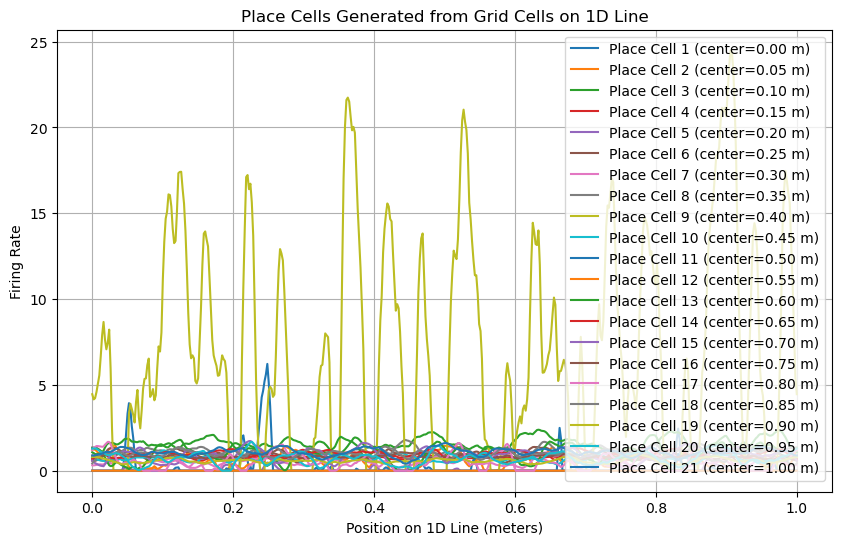

In [10]:
import numpy as np
import matplotlib.pyplot as plt

def generate_grid_cell_response_1d(position, grid_spacing, phase_offset, sigma, max_firing_rate):
    phase = (position + phase_offset) % grid_spacing
    response = max_firing_rate * np.exp(-0.5 * ((phase - grid_spacing / 2) ** 2) / sigma ** 2)
    return response

def generate_place_cell_activity_from_grid_cells_1d(position, grid_cell_params, place_cell_weights):
    grid_cell_responses = np.array([
        generate_grid_cell_response_1d(position, *params) for params in grid_cell_params
    ])
    place_cell_response = np.dot(place_cell_weights, grid_cell_responses)
    place_cell_response = np.maximum(0, place_cell_response)  # ReLU nonlinearity
    return place_cell_response

def plot_place_cells_generated_from_grid_cells_1d(line_length, place_cell_centers, grid_cell_params, resolution=500):
    positions = np.linspace(0, line_length, resolution)
    place_cell_activities = np.zeros((len(place_cell_centers), resolution))

    for i, center in enumerate(place_cell_centers):
        # Generate weights specifically designed for place cell i to peak at the desired location
        place_cell_weights = np.random.randn(len(grid_cell_params))
        place_cell_weights /= np.sum(place_cell_weights)  # Normalize weights
        
        for j, pos in enumerate(positions):
            place_cell_activities[i, j] = generate_place_cell_activity_from_grid_cells_1d(pos, grid_cell_params, place_cell_weights)
    
    plt.figure(figsize=(10, 6))
    for i, center in enumerate(place_cell_centers):
        plt.plot(positions, place_cell_activities[i], label=f'Place Cell {i+1} (center={center:.2f} m)')
    plt.xlabel('Position on 1D Line (meters)')
    plt.ylabel('Firing Rate')
    plt.title('Place Cells Generated from Grid Cells on 1D Line')
    plt.legend()
    plt.grid(True)
    plt.show()

# Example parameters
line_length = 1.0  # Length of the 1D environment in meters
spacing = 0.05  # 5 cm spacing between place cell centers
sigma = 0.02  # Width of the Gaussian bump for grid cells (in meters)
max_firing_rate = 1.0  # Maximum firing rate at the center of each place field

# Generate grid cell parameters (spacing, phase offset, sigma, max_firing_rate)
N_grid_cells = 50  # Number of grid cells
grid_cell_params = []
for i in range(N_grid_cells):
    grid_spacing = line_length / (i + 1)
    phase_offset = np.random.uniform(0, grid_spacing)  # Random phase offset
    grid_cell_params.append((grid_spacing, phase_offset, sigma, max_firing_rate))

# Define place cell centers, spaced 5 cm apart
place_cell_centers = np.arange(0, line_length + spacing, spacing)

# Plot place cells generated from grid cells
plot_place_cells_generated_from_grid_cells_1d(line_length, place_cell_centers, grid_cell_params)